# Drug-grouped outer 5-fold Multimodal evaluation

- Input: `dataset.csv` (전체 데이터)
- Outer split: `StratifiedGroupKFold(n_splits=5)`, group = **Drug**
- Inner split: outer-train 내부에서 다시 drug-group-aware train/validation 분할
- Early stopping / best checkpoint: **validation Macro-F1**
- Final performance: 각 outer **unseen-drug test fold**에서 평가 후 mean ± SD
- ROC/PR curves: outer test predictions 기반

원본 notebook의 CNN/GCN 구조와 one-hot/SMILES 전처리는 유지하고, split 및 평가 구조를 group-aware 방식으로 변경했습니다.


In [27]:
import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, auc, precision_recall_curve, roc_auc_score,
    average_precision_score, classification_report, confusion_matrix
)
import matplotlib.pyplot as plt

from torch_geometric.nn import global_mean_pool, GCNConv
from torch_geometric.data import Data, Batch
from rdkit import Chem

SEED = 2
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda:1' if torch.cuda.is_available() else 'cpu')
print('Device:', device)


Device: cuda:1


In [28]:
# ================================
# 전체 데이터 로드 및 label encoding
# ================================
data = pd.read_csv('dataset.csv')

required_cols = {'Variant', 'Drug', 'Class', 'isomeric'}
missing = required_cols - set(data.columns)
if missing:
    raise ValueError(f'Missing required columns: {missing}')

label_encoder = LabelEncoder()
data['Class_encoded'] = label_encoder.fit_transform(data['Class'])
class_mapping = {i: label for i, label in enumerate(label_encoder.classes_)}

print('Total samples:', len(data))
print('Number of drugs:', data['Drug'].nunique())
print('Class mapping:', class_mapping)
print('\nClass counts:')
print(data['Class'].value_counts())


Total samples: 622
Number of drugs: 59
Class mapping: {0: 'de', 1: 'f', 2: 'nor'}

Class counts:
de     250
f      195
nor    177
Name: Class, dtype: int64


In [29]:
#onehot 파일 폴더 경로
onehot_folder = 'onehot_7'
onehot_files = os.listdir(onehot_folder)

# 원핫인코딩 매트릭스를 저장할 딕셔너리
onehot_matrices = {}

# 최대 행 수 찾기
max_rows = 0

# 원핫인코딩 매트릭스 파일들을 로드 (헤더 없음)
for file in onehot_files:
    variant_name = file.split('.csv')[0].replace('_', '.')  # CYP2D6_1.001.csv -> CYP2D6.1.001
    file_path = os.path.join(onehot_folder, file)
    try:
        matrix = pd.read_csv(file_path, header=None).values
        onehot_matrices[variant_name] = matrix
        max_rows = max(max_rows, matrix.shape[0])
        print(f"Loaded {variant_name}: shape {matrix.shape}")
    except Exception as e:
        print(f"Error loading {file}: {str(e)}")

print(f"최대 행 수: {max_rows}")
print(f"로드된 매트릭스 개수: {len(onehot_matrices)}")

Loaded CYP2D6.106.002: shape (4312, 7)
Loaded CYP2D6.35.004: shape (4312, 7)
Loaded CYP2D6.2.004: shape (4312, 7)
Loaded CYP2D6.4.012: shape (4312, 7)
Loaded CYP2D6.36.002: shape (4312, 7)
Loaded CYP2D6.10.003: shape (4312, 7)
Loaded CYP2D6.1.050: shape (4312, 7)
Loaded CYP2D6.105.001: shape (4312, 7)
Loaded CYP2D6.159.001: shape (4312, 7)
Loaded CYP2D6.134.001: shape (4312, 7)
Loaded CYP2D6.155.001: shape (4312, 7)
Loaded CYP2D6.4.015: shape (4312, 7)
Loaded CYP2D6.11.001: shape (4312, 7)
Loaded CYP2D6.71.001: shape (4312, 7)
Loaded CYP2D6.4.003: shape (4312, 7)
Loaded CYP2D6.47.001: shape (4312, 7)
Loaded CYP2D6.4.010: shape (4312, 7)
Loaded CYP2D6.4.024: shape (4312, 7)
Loaded CYP2D6.2.015: shape (4312, 7)
Loaded CYP2D6.164.001: shape (4312, 7)
Loaded CYP2D6.85.001: shape (4312, 7)
Loaded CYP2D6.3.002: shape (4312, 7)
Loaded CYP2D6.1.035: shape (4312, 7)
Loaded CYP2D6.3.003: shape (4312, 7)
Loaded CYP2D6.97.001: shape (4312, 7)
Loaded CYP2D6.1.013: shape (4312, 7)
Loaded CYP2D6.4.00

In [30]:
# ================================
# Variant -> one-hot tensor
# ================================
def pad_matrix(matrix, target_rows=4330, target_cols=7):
    current_rows, current_cols = matrix.shape
    padded = torch.zeros((target_rows, target_cols), dtype=torch.float32)
    padded[:current_rows, :current_cols] = torch.tensor(matrix, dtype=torch.float32)
    return padded

for key in onehot_matrices:
    onehot_matrices[key] = pad_matrix(onehot_matrices[key])

def map_variant_to_onehot(variant):
    variants = str(variant).split('; ')
    matrices = []
    for v in variants:
        if v in onehot_matrices:
            matrices.append(onehot_matrices[v])
        else:
            print(f'Warning: Matrix not found for variant {v}')
            matrices.append(torch.zeros((4330, 7), dtype=torch.float32))
    while len(matrices) < 2:
        matrices.append(torch.zeros((4330, 7), dtype=torch.float32))
    return torch.vstack(matrices[:2])

def map_variants_to_tensor(df):
    X = torch.stack([map_variant_to_onehot(v) for v in df['Variant']])
    y = torch.tensor(df['Class_encoded'].values, dtype=torch.long)
    return X, y

all_X, all_y = map_variants_to_tensor(data)
cnn_data = all_X.unsqueeze(1)
smiles_data = data['isomeric'].values
labels = all_y

print('CNN data shape:', cnn_data.shape)
print('Labels shape:', labels.shape)


CNN data shape: torch.Size([622, 1, 8660, 7])
Labels shape: torch.Size([622])


In [31]:
# One-hot encoding 함수를 정의
def one_of_k_encoding(x, allowable_set):
    if x not in allowable_set:
        x = allowable_set[-1]
    return [int(x == s) for s in allowable_set]

# 원자 특징을 one-hot 인코딩하는 함수
def atom_to_onehot_features(atom):
    symbol_one_hot = one_of_k_encoding(
        atom.GetSymbol(), 
        ['H', 'C', 'N', 'O', 'F', 'P', 'S', 'Cl', 'Br', 'I', 'other'])  # 원자 기호를 one-hot으로 인코딩
    
    degree_one_hot = one_of_k_encoding(atom.GetDegree(), [0, 1, 2, 3, 4, 5])  # 결합수
    explicit_valence_one_hot = one_of_k_encoding(atom.GetExplicitValence(), [0, 1, 2, 3, 4, 5, 6])  # 명시적 원자가
    implicit_valence_one_hot = one_of_k_encoding(atom.GetImplicitValence(), [0, 1, 2, 3, 4, 5])  # 암묵적 원자가
    formal_charge_one_hot = one_of_k_encoding(atom.GetFormalCharge(), [-1, 0, 1])  # 형식 전하
    hybridization_one_hot = one_of_k_encoding(atom.GetHybridization(), 
        [Chem.rdchem.HybridizationType.SP, Chem.rdchem.HybridizationType.SP2, Chem.rdchem.HybridizationType.SP3, 'other'])  # 혼성화
    aromatic_one_hot = [atom.GetIsAromatic()]  # 방향족성 (True/False)
    # Chiral tag을 one-hot 인코딩으로 추가
    chiral_tag_one_hot = one_of_k_encoding(atom.GetChiralTag(), 
        [Chem.rdchem.ChiralType.CHI_UNSPECIFIED, 
         Chem.rdchem.ChiralType.CHI_TETRAHEDRAL_CW, 
         Chem.rdchem.ChiralType.CHI_TETRAHEDRAL_CCW, 
         Chem.rdchem.ChiralType.CHI_OTHER])  # 입체화학 정보
    
    # 모든 one-hot 인코딩된 벡터들을 하나로 결합
    return symbol_one_hot + degree_one_hot + explicit_valence_one_hot + implicit_valence_one_hot + formal_charge_one_hot + hybridization_one_hot + aromatic_one_hot + chiral_tag_one_hot

# SMILES to Graph conversion with one-hot encoding for atom features
def smiles_to_graph(smiles):
    mol = Chem.MolFromSmiles(smiles)
    mol = Chem.AddHs(mol)
    
    atom_features = []
    for atom in mol.GetAtoms():
        atom_features.append(atom_to_onehot_features(atom))  # 각 원자를 one-hot 인코딩
    
    # x는 (N, F) 크기의 텐서, 여기서 N은 원자의 수, F는 특징 벡터의 크기
    x = torch.tensor(atom_features, dtype=torch.float)
    
    # bond 연결 정보를 edge_index로 저장
    rows, cols = [], []
    for bond in mol.GetBonds():
        start, end = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        rows += [start, end]
        cols += [end, start]
    
    edge_index = torch.tensor([rows, cols], dtype=torch.long)
    
    return Data(x=x, edge_index=edge_index)


In [32]:
# ================================
# Dataset / collate
# ================================
class MultimodalDataset(Dataset):
    def __init__(self, cnn_data, smiles_data, labels):
        self.cnn_data = cnn_data
        self.smiles_data = smiles_data
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        cnn_input = self.cnn_data[idx]
        gcn_data = smiles_to_graph(self.smiles_data[idx])
        label = self.labels[idx]
        return cnn_input, gcn_data, label

def collate_fn(batch):
    cnn_inputs, gcn_data, labels_batch = zip(*batch)
    return (
        torch.stack(cnn_inputs),
        Batch.from_data_list(gcn_data),
        torch.stack(labels_batch)
    )

dataset = MultimodalDataset(cnn_data, smiles_data, labels)
batch_size = 32


In [33]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=8, kernel_size=(20, 7), stride=(1, 1))
        self.pool1 = nn.MaxPool2d(kernel_size=(2, 1))  
        self.conv2 = nn.Conv2d(in_channels=8, out_channels=16, kernel_size=(20, 1), stride=(1, 1))
        self.pool2 = nn.MaxPool2d(kernel_size=(2, 1))

        # Fully Connected Layer에서 최종 벡터 크기를 128로 맞춤
        self.fc1 = nn.Linear(34400, 512)  # 2150 차원으로 수정
        self.fc2 = nn.Linear(512, 128)  # 2150 차원으로 수정

    def forward(self, x):
        x = self.conv1(x)
        x = nn.ReLU()(x)     
        x = self.pool1(x)
        x = self.conv2(x)
        x = nn.ReLU()(x)
        x = self.pool2(x)
        x = x.view(x.size(0), -1)  # Flattening
        x = self.fc1(x)  # 512 크기의 벡터를 생성
        x = nn.ReLU()(x)
        x = self.fc2(x)  # 128 크기의 벡터를 생성
        x = nn.ReLU()(x)
        return x 

In [34]:
class GCNModel(nn.Module):
    def __init__(self, num_node_features, hidden_channels):  #, dropout_rate=0.5):
        super(GCNModel, self).__init__()
        self.conv1 = GCNConv(num_node_features, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)
        self.conv3 = GCNConv(hidden_channels, hidden_channels)
        
        # BatchNorm layers
        self.bn1 = nn.BatchNorm1d(hidden_channels)
        self.bn2 = nn.BatchNorm1d(hidden_channels)
        self.bn3 = nn.BatchNorm1d(hidden_channels)

        # Dropout layer
        #self.dropout = nn.Dropout(0.5)

        # Fully Connected Layer
        self.fc = nn.Linear(hidden_channels, 128)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index

        x = self.conv1(x, edge_index)
        x = self.bn1(x)
        x = F.relu(x)
        #x = self.dropout(x)  
        
        x = self.conv2(x, edge_index)
        x = self.bn2(x)
        x = F.relu(x)
        #x = self.dropout(x)  
        
        x = self.conv3(x, edge_index)
        x = self.bn3(x)

        x = global_mean_pool(x, data.batch)

        x = self.fc(x)
        x = F.relu(x)
        
        return x

In [35]:
class MultimodalModel(nn.Module):
    def __init__(self, cnn_model, gcn_model, cnn_output_dim, gcn_output_dim, num_classes):
        super(MultimodalModel, self).__init__()
        self.cnn_model = cnn_model
        self.gcn_model = gcn_model

        # CNN과 GCN 벡터를 합친 후 사용할 Fully Connected Layer
        self.fc1 = nn.Linear(cnn_output_dim + gcn_output_dim, 64)
        self.fc2 = nn.Linear(64, num_classes)

    def forward(self, cnn_input, gcn_data):
        # CNN에서 128차원 벡터 추출
        cnn_output = self.cnn_model(cnn_input)

        # GCN에서 128차원 벡터 추출
        gcn_output = self.gcn_model(gcn_data)

        # CNN과 GCN 벡터를 결합
        combined = torch.cat([cnn_output, gcn_output], dim=1)

        # Fully Connected Layer
        x = self.fc1(combined)
        x = F.relu(x)
        x = self.fc2(x)
        return x

## Evaluation utilities
Macro-Precision/Recall/F1, Macro-AUROC (OvR), Macro-AUPR (OvR)를 사용합니다.


In [36]:
def compute_macro_aupr(y_true, y_probs, num_classes=3):
    class_auprs = []
    for i in range(num_classes):
        y_binary = (y_true == i).astype(int)
        if y_binary.sum() == 0:
            class_auprs.append(np.nan)
        else:
            class_auprs.append(average_precision_score(y_binary, y_probs[:, i]))
    return float(np.nanmean(class_auprs))

def compute_macro_auc(y_true, y_probs, num_classes=3):
    class_aucs = []
    for i in range(num_classes):
        y_binary = (y_true == i).astype(int)
        pos = y_binary.sum()
        neg = len(y_binary) - pos
        if pos == 0 or neg == 0:
            class_aucs.append(np.nan)
        else:
            class_aucs.append(roc_auc_score(y_binary, y_probs[:, i]))
    return float(np.nanmean(class_aucs))

def evaluate_model(model, loader, criterion, device, num_classes=3):
    model.eval()
    total_loss, total, correct = 0.0, 0, 0
    all_labels, all_logits = [], []

    with torch.no_grad():
        for cnn_inputs, gcn_batch, labels_batch in loader:
            cnn_inputs = cnn_inputs.to(device)
            gcn_batch = gcn_batch.to(device)
            labels_batch = labels_batch.to(device)
            outputs = model(cnn_inputs, gcn_batch)
            loss = criterion(outputs, labels_batch)
            total_loss += loss.item()
            pred = outputs.argmax(dim=1)
            total += labels_batch.size(0)
            correct += (pred == labels_batch).sum().item()
            all_labels.append(labels_batch.cpu())
            all_logits.append(outputs.cpu())

    y_true = torch.cat(all_labels).numpy()
    logits = torch.cat(all_logits)
    y_probs = F.softmax(logits, dim=1).numpy()
    y_pred = y_probs.argmax(axis=1)

    return {
        'loss': total_loss / len(loader),
        'accuracy': correct / total,
        'precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'auc': compute_macro_auc(y_true, y_probs, num_classes),
        'aupr': compute_macro_aupr(y_true, y_probs, num_classes),
        'y_true': y_true,
        'y_pred': y_pred,
        'y_probs': y_probs
    }


## Group-aware split
Outer test drug와 train/validation drug가 겹치지 않도록 합니다. Inner validation도 Drug group 기준으로 분리합니다.


In [37]:
N_OUTER_SPLITS = 5
N_INNER_SPLITS = 10
TARGET_VAL_N = 80

outer_cv = StratifiedGroupKFold(
    n_splits=N_OUTER_SPLITS,
    shuffle=True,
    random_state=SEED
)

outer_splits = list(
    outer_cv.split(
        X=np.zeros(len(data)),
        y=data['Class_encoded'].values,
        groups=data['Drug'].astype(str).values
    )
)


def make_inner_train_val_split(
    outer_train_idx,
    df,
    random_state,
    target_val_n=TARGET_VAL_N
):
    outer_train_df = df.iloc[outer_train_idx]

    inner_cv = StratifiedGroupKFold(
        n_splits=N_INNER_SPLITS,
        shuffle=True,
        random_state=random_state
    )

    best_split = None
    best_diff = float('inf')

    for inner_train_local, val_local in inner_cv.split(
        X=np.zeros(len(outer_train_df)),
        y=outer_train_df['Class_encoded'].values,
        groups=outer_train_df['Drug'].astype(str).values
    ):
        diff = abs(len(val_local) - target_val_n)

        if diff < best_diff:
            best_diff = diff
            best_split = (
                inner_train_local,
                val_local
            )

    inner_train_local, val_local = best_split

    return (
        outer_train_idx[inner_train_local],
        outer_train_idx[val_local]
    )

## Training + outer test evaluation
- Best checkpoint / patience: validation Macro-F1
- Test fold는 학습 및 checkpoint 선택에 사용하지 않습니다.
- Optimizer에는 CNN, GCN, fusion FC layer를 포함한 **전체 multimodal model parameter**를 넣습니다.


In [38]:
NUM_EPOCHS = 150
PATIENCE = 30
cnn_lr = 0.0005
gcn_lr = 0.00025
fc_lr = 0.0005

criterion = nn.CrossEntropyLoss().to(device)
test_results = []
all_test_labels_list = []
all_test_preds_list = []
fold_assignments = []

for fold, (outer_train_idx, test_idx) in enumerate(outer_splits):
    print('\n' + '=' * 80)
    print(f'OUTER FOLD {fold + 1}/{N_OUTER_SPLITS}')
    print('=' * 80)

    train_idx, val_idx = make_inner_train_val_split(
        outer_train_idx, data, random_state=100 + fold
    )

    train_drugs = set(data.iloc[train_idx]['Drug'].astype(str))
    val_drugs = set(data.iloc[val_idx]['Drug'].astype(str))
    test_drugs = set(data.iloc[test_idx]['Drug'].astype(str))

    assert train_drugs.isdisjoint(val_drugs)
    assert train_drugs.isdisjoint(test_drugs)
    assert val_drugs.isdisjoint(test_drugs)

    print(f'Train: {len(train_idx)} samples / {len(train_drugs)} drugs')
    print(f'Val  : {len(val_idx)} samples / {len(val_drugs)} drugs')
    print(f'Test : {len(test_idx)} samples / {len(test_drugs)} drugs')
    print('Test drugs:', sorted(test_drugs))
    print('Train class counts:', data.iloc[train_idx]['Class'].value_counts().to_dict())
    print('Val class counts  :', data.iloc[val_idx]['Class'].value_counts().to_dict())
    print('Test class counts :', data.iloc[test_idx]['Class'].value_counts().to_dict())

    train_loader = DataLoader(Subset(dataset, train_idx), batch_size=batch_size, shuffle=True, collate_fn=collate_fn)
    val_loader = DataLoader(Subset(dataset, val_idx), batch_size=batch_size, shuffle=False, collate_fn=collate_fn)
    test_loader = DataLoader(Subset(dataset, test_idx), batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

    cnn_model = SimpleCNN().to(device)
    gcn_model = GCNModel(num_node_features=42, hidden_channels=64).to(device)
    multimodal_model = MultimodalModel(
        cnn_model, gcn_model, cnn_output_dim=128, gcn_output_dim=128, num_classes=3
    ).to(device)

    # 전체 multimodal parameter 학습 (fusion fc1/fc2 포함)
    optimizer = torch.optim.Adam([
        {'params': multimodal_model.cnn_model.parameters(), 'lr': cnn_lr},
        {'params': multimodal_model.gcn_model.parameters(), 'lr': gcn_lr},
        {'params': multimodal_model.fc1.parameters(),       'lr': fc_lr},
        {'params': multimodal_model.fc2.parameters(),       'lr': fc_lr},
    ])

    best_val_f1 = -np.inf
    patience_counter = 0
    best_model_path = f'best_drug_grouped_fold_{fold}.pth'

    for epoch in range(NUM_EPOCHS):
        multimodal_model.train()
        total_train_loss, total_train, correct_train = 0.0, 0, 0

        for cnn_inputs, gcn_batch, labels_batch in train_loader:
            cnn_inputs = cnn_inputs.to(device)
            gcn_batch = gcn_batch.to(device)
            labels_batch = labels_batch.to(device)

            optimizer.zero_grad()
            outputs = multimodal_model(cnn_inputs, gcn_batch)
            loss = criterion(outputs, labels_batch)
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item()
            pred = outputs.argmax(dim=1)
            total_train += labels_batch.size(0)
            correct_train += (pred == labels_batch).sum().item()

        train_loss = total_train_loss / len(train_loader)
        train_acc = correct_train / total_train
        val_metrics = evaluate_model(multimodal_model, val_loader, criterion, device)

        print(
            f'Epoch [{epoch+1:02d}/{NUM_EPOCHS}] | '
            f'Train Loss {train_loss:.4f} Acc {train_acc:.4f} | '
            f'Val Loss {val_metrics["loss"]:.4f} Acc {val_metrics["accuracy"]:.4f} | '
            f'Val Macro-F1 {val_metrics["f1"]:.4f} AUC {val_metrics["auc"]:.4f} AUPR {val_metrics["aupr"]:.4f}'
        )

        if val_metrics['f1'] > best_val_f1:
            best_val_f1 = val_metrics['f1']
            patience_counter = 0
            torch.save(multimodal_model.state_dict(), best_model_path)
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                print('Early stopping applied.')
                break

    # best validation checkpoint를 다시 로드한 뒤 outer test 평가
    multimodal_model.load_state_dict(torch.load(best_model_path, map_location=device))
    multimodal_model.eval()

    best_val_metrics = evaluate_model(multimodal_model, val_loader, criterion, device)
    test_metrics = evaluate_model(multimodal_model, test_loader, criterion, device)

    print(f'Best Val Macro-F1: {best_val_metrics["f1"]:.4f}')
    print('*** OUTER TEST ***')
    print(
        f'Acc {test_metrics["accuracy"]:.4f} | Macro-Precision {test_metrics["precision"]:.4f} | '
        f'Macro-Recall {test_metrics["recall"]:.4f} | Macro-F1 {test_metrics["f1"]:.4f} | '
        f'Macro-AUROC {test_metrics["auc"]:.4f} | Macro-AUPR {test_metrics["aupr"]:.4f}'
    )

    test_results.append({
        'fold': fold + 1,
        'n_train': len(train_idx), 'n_val': len(val_idx), 'n_test': len(test_idx),
        'n_train_drugs': len(train_drugs), 'n_val_drugs': len(val_drugs), 'n_test_drugs': len(test_drugs),
        'accuracy': test_metrics['accuracy'], 'precision': test_metrics['precision'],
        'recall': test_metrics['recall'], 'f1': test_metrics['f1'],
        'auc': test_metrics['auc'], 'aupr': test_metrics['aupr']
    })
    all_test_labels_list.append(test_metrics['y_true'])
    all_test_preds_list.append(test_metrics['y_probs'])

    for split_name, indices in [('train', train_idx), ('validation', val_idx), ('test', test_idx)]:
        for idx in indices:
            fold_assignments.append({
                'sample_index': int(idx), 'outer_fold': fold + 1, 'set': split_name,
                'Drug': data.iloc[idx]['Drug'], 'Variant': data.iloc[idx]['Variant'], 'Class': data.iloc[idx]['Class']
            })



OUTER FOLD 1/5
Train: 454 samples / 43 drugs
Val  : 74 samples / 4 drugs
Test : 94 samples / 12 drugs
Test drugs: ['citalopram', 'codeine', 'desmethyltamoxifen', 'dextromethorphan', 'donepezil', 'fluvoxamine', 'mianserin', 'mirtazapine', 'opipramol', 'timolol', 'tropisetron', 'zuclopenthixol']
Train class counts: {'de': 182, 'nor': 143, 'f': 129}
Val class counts  : {'de': 29, 'f': 29, 'nor': 16}
Test class counts : {'de': 39, 'f': 37, 'nor': 18}
Epoch [01/150] | Train Loss 1.0907 Acc 0.4009 | Val Loss 1.1135 Acc 0.3919 | Val Macro-F1 0.1877 AUC 0.6118 AUPR 0.4656
Epoch [02/150] | Train Loss 1.0741 Acc 0.3987 | Val Loss 1.1038 Acc 0.3919 | Val Macro-F1 0.1877 AUC 0.7338 AUPR 0.5651
Epoch [03/150] | Train Loss 1.0567 Acc 0.4295 | Val Loss 1.0958 Acc 0.4324 | Val Macro-F1 0.2801 AUC 0.7225 AUPR 0.5486
Epoch [04/150] | Train Loss 1.0370 Acc 0.4471 | Val Loss 1.0407 Acc 0.3649 | Val Macro-F1 0.3551 AUC 0.7258 AUPR 0.5329
Epoch [05/150] | Train Loss 1.0071 Acc 0.4824 | Val Loss 1.0680 Acc 

## Outer-test performance summary


In [39]:
results_df = pd.DataFrame(test_results)
display(results_df)

print('\n=== Drug-grouped Outer 5-fold TEST Results ===')
for metric in ['accuracy', 'precision', 'recall', 'f1', 'auc', 'aupr']:
    vals = results_df[metric].values.astype(float)
    print(f'{metric}: {np.nanmean(vals):.4f} ± {np.nanstd(vals):.4f}')

results_df.to_csv('drug_grouped_outer5fold_results.csv', index=False)
pd.DataFrame(fold_assignments).to_csv('drug_grouped_fold_assignments.csv', index=False)
print('\nSaved: drug_grouped_outer5fold_results.csv')
print('Saved: drug_grouped_fold_assignments.csv')


,fold,n_train,n_val,n_test,n_train_drugs,n_val_drugs,n_test_drugs,accuracy,precision,recall,f1,auc,aupr
0,1,454,74,94,43,4,12,0.776596,0.764055,0.798260,0.766276,0.932630,0.869253
1,2,425,78,119,42,6,11,0.823529,0.833169,0.838424,0.827539,0.945921,0.905830
2,3,394,73,155,39,8,12,0.754839,0.846515,0.755279,0.751725,0.955251,0.903214
3,4,431,83,108,42,6,11,0.805556,0.829710,0.810657,0.808396,0.937905,0.893827
4,5,396,80,146,41,5,13,0.773973,0.788961,0.805787,0.791135,0.898677,0.828129



=== Drug-grouped Outer 5-fold TEST Results ===
accuracy: 0.7869 ± 0.0245
precision: 0.8125 ± 0.0309
recall: 0.8017 ± 0.0269
f1: 0.7890 ± 0.0275
auc: 0.9341 ± 0.0193
aupr: 0.8801 ± 0.0290

Saved: drug_grouped_outer5fold_results.csv
Saved: drug_grouped_fold_assignments.csv


## ROC curve — outer test folds


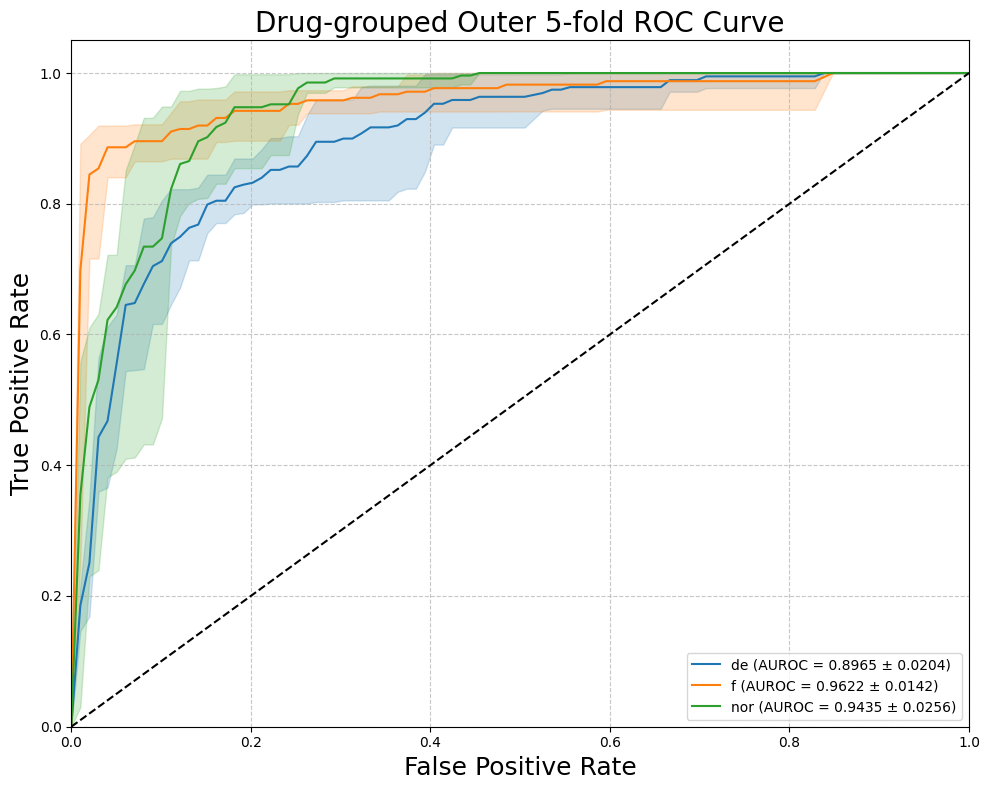

In [40]:
def plot_mean_roc_curve(y_true_list, y_probs_list, num_classes=3, font_size=18):
    plt.figure(figsize=(10, 8))
    mean_fpr = np.linspace(0, 1, 100)

    for i in range(num_classes):
        tprs, fold_aucs = [], []
        for y_true, y_probs in zip(y_true_list, y_probs_list):
            y_bin = (y_true == i).astype(int)
            if y_bin.sum() == 0 or y_bin.sum() == len(y_bin):
                continue
            fpr, tpr, _ = roc_curve(y_bin, y_probs[:, i])
            interp_tpr = np.interp(mean_fpr, fpr, tpr)
            interp_tpr[0] = 0.0
            tprs.append(interp_tpr)
            fold_aucs.append(auc(fpr, tpr))

        if not tprs:
            continue
        tprs = np.asarray(tprs)
        mean_tpr = np.mean(tprs, axis=0)
        mean_tpr[-1] = 1.0
        lower = np.percentile(tprs, 2.5, axis=0)
        upper = np.percentile(tprs, 97.5, axis=0)
        label = f'{class_mapping[i]} (AUROC = {np.mean(fold_aucs):.4f} ± {np.std(fold_aucs):.4f})'
        line, = plt.plot(mean_fpr, mean_tpr, label=label)
        plt.fill_between(mean_fpr, lower, upper, alpha=0.2, color=line.get_color())

    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0, 1]); plt.ylim([0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=font_size)
    plt.ylabel('True Positive Rate', fontsize=font_size)
    plt.title('Drug-grouped Outer 5-fold ROC Curve', fontsize=font_size + 2)
    plt.legend(loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

plot_mean_roc_curve(all_test_labels_list, all_test_preds_list)


## Precision–Recall curve — outer test folds


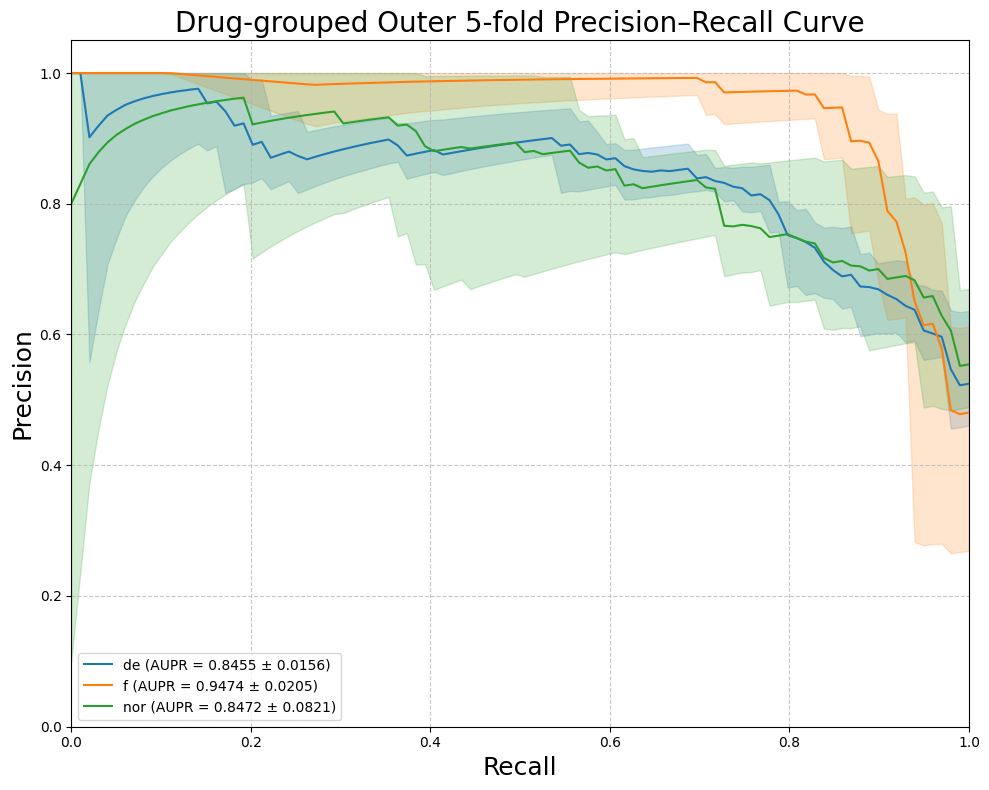

In [41]:
def plot_mean_pr_curve(y_true_list, y_probs_list, num_classes=3, font_size=18):
    plt.figure(figsize=(10, 8))
    mean_recall = np.linspace(0, 1, 100)

    for i in range(num_classes):
        interp_precisions, fold_auprs = [], []
        for y_true, y_probs in zip(y_true_list, y_probs_list):
            y_bin = (y_true == i).astype(int)
            if y_bin.sum() == 0:
                continue
            precision, recall, _ = precision_recall_curve(y_bin, y_probs[:, i])
            interp_precision = np.interp(mean_recall, recall[::-1], precision[::-1])
            interp_precisions.append(interp_precision)
            fold_auprs.append(average_precision_score(y_bin, y_probs[:, i]))

        if not interp_precisions:
            continue
        interp_precisions = np.asarray(interp_precisions)
        mean_precision = np.mean(interp_precisions, axis=0)
        lower = np.percentile(interp_precisions, 2.5, axis=0)
        upper = np.percentile(interp_precisions, 97.5, axis=0)
        label = f'{class_mapping[i]} (AUPR = {np.mean(fold_auprs):.4f} ± {np.std(fold_auprs):.4f})'
        line, = plt.plot(mean_recall, mean_precision, label=label)
        plt.fill_between(mean_recall, lower, upper, alpha=0.2, color=line.get_color())

    plt.xlim([0, 1]); plt.ylim([0, 1.05])
    plt.xlabel('Recall', fontsize=font_size)
    plt.ylabel('Precision', fontsize=font_size)
    plt.title('Drug-grouped Outer 5-fold Precision–Recall Curve', fontsize=font_size + 2)
    plt.legend(loc='lower left')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

plot_mean_pr_curve(all_test_labels_list, all_test_preds_list)
